<a href="https://colab.research.google.com/github/mohitt770/ML_LAB/blob/main/electrical_motor_fault_prediction_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Cell 1: Mount Drive & Import Libraries

In [4]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
import joblib

# Sklearn utilities & preprocessing
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Models (Total 4 Models)
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Upload your dataset CSV
Run the cell and select the actual `train.csv` file from your computer. Do not upload this `.ipynb` notebook as the dataset.

In [5]:
uploaded = files.upload()  # Select train.csv
csv_files = [name for name in uploaded if name.lower().endswith(".csv")]
if not csv_files:
    raise ValueError("No CSV file uploaded. Download and upload the dataset's train.csv file.")
file_name = csv_files[0]
df = pd.read_csv(file_name)

# Make column names easier to work with while retaining original meaning
df.columns = [c.strip() for c in df.columns]
print("Loaded:", file_name)
print("Dataset shape:", df.shape)
display(df.head())
print("\\nColumns:", df.columns.tolist())

Saving train.csv to train (1).csv
Loaded: train (1).csv
Dataset shape: (136429, 14)


,id,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,0,L50096,L,300.6,309.6,1596,36.1,140,0,0,0,0,0,0
1,1,M20343,M,302.6,312.1,1759,29.1,200,0,0,0,0,0,0
2,2,L49454,L,299.3,308.5,1805,26.5,25,0,0,0,0,0,0
3,3,L53355,L,301.0,310.9,1524,44.3,197,0,0,0,0,0,0
4,4,M24050,M,298.0,309.0,1641,35.4,34,0,0,0,0,0,0


\nColumns: ['id', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


## 3. Check the dataset and target

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 136429 entries, 0 to 136428
Data columns (total 14 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id                       136429 non-null  int64  
 1   Product ID               136429 non-null  object 
 2   Type                     136429 non-null  object 
 3   Air temperature [K]      136429 non-null  float64
 4   Process temperature [K]  136429 non-null  float64
 5   Rotational speed [rpm]   136429 non-null  int64  
 6   Torque [Nm]              136429 non-null  float64
 7   Tool wear [min]          136429 non-null  int64  
 8   Machine failure          136429 non-null  int64  
 9   TWF                      136429 non-null  int64  
 10  HDF                      136429 non-null  int64  
 11  PWF                      136429 non-null  int64  
 12  OSF                      136429 non-null  int64  
 13  RNF                      136429 non-nu

,missing_values
id,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0


\nTarget distribution:


,count
Machine failure,
No failure (0),134281
Failure (1),2148


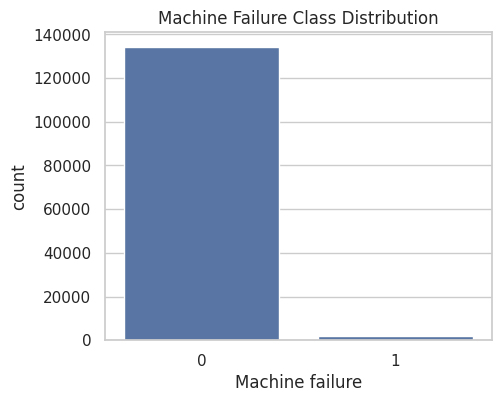

In [6]:
print("Dataset information:")
df.info()
print("\\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_values"))
print("\\nTarget distribution:")
if "Machine failure" not in df.columns:
    raise ValueError("Target column 'Machine failure' was not found. Please upload the labelled training CSV.")
display(df["Machine failure"].value_counts(dropna=False).rename(index={0: "No failure (0)", 1: "Failure (1)"}).to_frame("count"))

plt.figure(figsize=(5, 4))
sns.countplot(data=df, x="Machine failure")
plt.title("Machine Failure Class Distribution")
plt.show()

## 4. Prepare features and target
We remove identifiers because they generally do not describe machine condition. If the dataset contains `id` or `Product ID`, those columns are excluded. The target is `Machine failure`.

In [7]:
target = "Machine failure"
drop_candidates = [c for c in ["id", "ID", "Product ID"] if c in df.columns]
data = df.drop(columns=drop_candidates).copy()

# Convert target to numeric and remove rows without a target
data[target] = pd.to_numeric(data[target], errors="coerce")
data = data.dropna(subset=[target])
data[target] = data[target].astype(int)

X = data.drop(columns=[target])
y = data[target]

# Use stratification so both classes are represented in train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

categorical_features = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Rows:", len(data))
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))

Rows: 136429
Numeric features: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']
Categorical features: ['Type']
Training rows: 109143 | Test rows: 27286


Cell 5: Multi-Model Training & Evaluation (Comparison Step)

In [9]:
models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        max_depth=10,
        random_state=RANDOM_STATE
    ),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=RANDOM_STATE
    )
}

results = []
trained_pipelines = {}

for model_name, classifier in models.items():
    print(f"Training {model_name}...")

    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    pipe.fit(X_train, y_train)
    trained_pipelines[model_name] = pipe

    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]

    results.append({
        "Model": model_name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Precision": round(precision_score(y_test, y_pred, zero_division=0), 4),
        "Recall": round(recall_score(y_test, y_pred, zero_division=0), 4),
        "F1-Score": round(f1_score(y_test, y_pred, zero_division=0), 4),
        "ROC-AUC": round(roc_auc_score(y_test, y_prob), 4)
    })

comparison_df = pd.DataFrame(results).sort_values(by="F1-Score", ascending=False)
display(comparison_df)

Training Logistic Regression...


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Training Decision Tree...
Training HistGradientBoosting...
Training Random Forest...


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
3,Random Forest,0.9958,0.9292,0.7930,0.8557,0.9573
2,HistGradientBoosting,0.9746,0.3683,0.8581,0.5154,0.9535
0,Logistic Regression,0.9749,0.3675,0.8256,0.5086,0.9306
1,Decision Tree,0.9599,0.2592,0.8326,0.3954,0.9153


Cell 6: Visual Comparison (ROC Curves & Best Model Confusion Matrix)

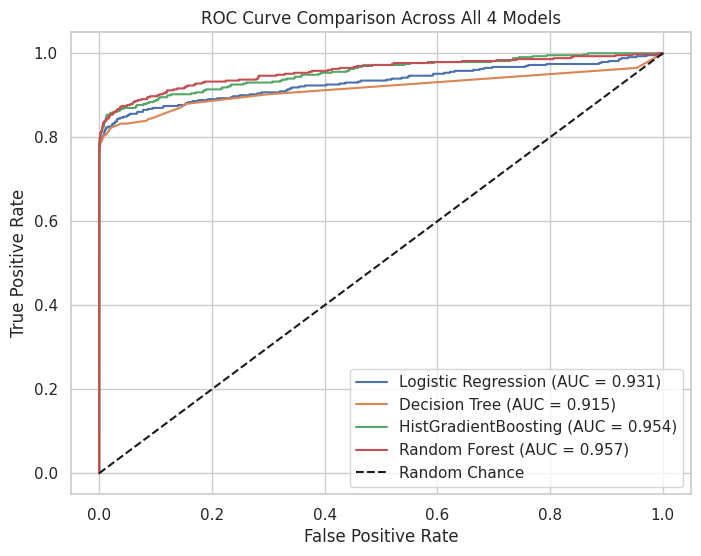

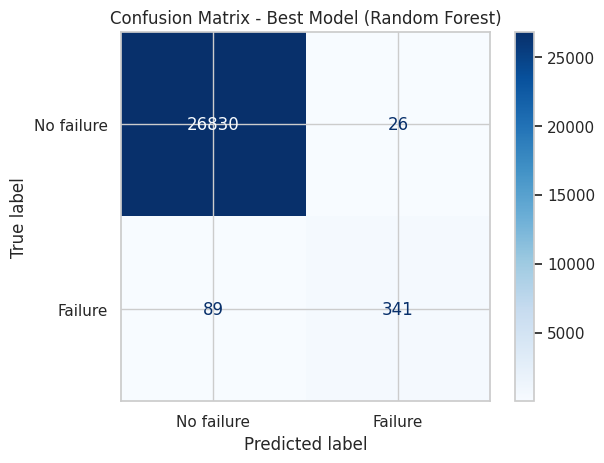

In [10]:
plt.figure(figsize=(8, 6))

for model_name, pipe in trained_pipelines.items():
    y_prob = pipe.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_val = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{model_name} (AUC = {auc_val:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison Across All 4 Models")
plt.legend()
plt.show()

# Best model (Random Forest) confusion matrix
best_model = trained_pipelines["Random Forest"]
y_pred_best = best_model.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_best, display_labels=["No failure", "Failure"], cmap="Blues"
)
plt.title("Confusion Matrix - Best Model (Random Forest)")
plt.show()

Cell 7: Sample Predictions Table

In [11]:
results_table = X_test.copy()
results_table["Actual Failure"] = y_test
results_table["Predicted Failure"] = best_model.predict(X_test)
results_table["Failure Probability"] = best_model.predict_proba(X_test)[:, 1]

display(results_table.head(10))

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],TWF,HDF,PWF,OSF,RNF,Actual Failure,Predicted Failure,Failure Probability
108143,L,303.3,311.2,1619,31.1,219,0,0,0,0,0,0,0,0.031052
124027,L,298.5,309.8,1663,36.1,203,0,0,0,0,0,0,0,0.025496
40415,M,297.0,308.1,1548,38.2,0,0,0,0,0,0,0,0,0.002344
5055,L,298.0,309.5,1599,35.7,51,0,0,0,0,0,0,0,0.001728
75315,L,296.9,307.8,1567,35.0,121,0,0,0,0,0,0,0,0.000500
129023,L,300.6,311.4,1446,40.3,75,0,0,0,0,0,0,0,0.000397
3698,L,298.8,310.5,1544,46.4,207,0,0,0,0,0,0,0,0.063637
11129,L,300.5,310.5,1536,40.2,12,0,0,0,0,0,0,0,0.000810
131286,M,297.6,309.3,1474,46.2,24,0,0,0,0,0,0,0,0.005219
11521,L,298.2,307.6,1369,50.7,82,0,0,0,0,0,0,0,0.021502


Cell 8: Prediction Helper Function

In [12]:
def predict_motor_failure(readings: dict):
    sample = pd.DataFrame([readings])
    sample = sample[X.columns]

    prediction = int(best_model.predict(sample)[0])
    probability = float(best_model.predict_proba(sample)[0, 1])
    label = "FAILURE PREDICTED" if prediction == 1 else "NO FAILURE PREDICTED"

    return {"prediction": label, "failure_probability": round(probability, 4)}

example_reading = X.iloc[0].to_dict()
print("Test Input Prediction:", predict_motor_failure(example_reading))

Test Input Prediction: {'prediction': 'NO FAILURE PREDICTED', 'failure_probability': 0.0013}


Cell 9: Save the Best Model

In [13]:
model_path = "best_motor_fault_model.joblib"
joblib.dump(best_model, model_path)
print("Saved model to:", model_path)
files.download(model_path)

Saved model to: best_motor_fault_model.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>